In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt 
from itertools import product
from aux_func import get_data, code_to_state, color_palette, estado_para_regiao, rename_models


# Definir a cor das bordas (spines) como cinza
mpl.rcParams['axes.edgecolor'] = 'gray'

# Definir a cor das linhas dos ticks maiores e menores como cinza
mpl.rcParams['xtick.color'] = 'gray'
mpl.rcParams['ytick.color'] = 'gray'
mpl.rcParams['xtick.labelcolor'] = 'black'
mpl.rcParams['ytick.labelcolor'] = 'black'
plt.rcParams['axes.labelsize'] = 16 # Axis labels
plt.rcParams['xtick.labelsize'] = 14  # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 14  # Y-axis tick labels
plt.rcParams['font.size'] = 16  # General font size
FONT = 12

Select challenge: 

In [ ]:
challenge = 'chik_state'

Load rank: 

In [3]:
remove_models = ['3rd_imdc_-unifesp-_-4mosqueteiras-',
                                      '3rd_imdc_fiocruz_zerolags',
                                        '3rd_imdc_rki_rki_zki_ph',
                               '3rd_imdc_rki_rki_zki_ph_lstm_geo',
                                         '3rd_imdc_unesp_recogna',
 '3rd_imdc_universidad_del_valle_grupo_modelamiento_datos_dengue', 
 '3rd_imdc_procc_bb_model']

In [4]:
df_rank = pd.read_csv(f'predictions/rank_ratio_{challenge}.csv')

df_rank = df_rank.loc[(df_rank.adm_1 != 32)]


df_rank = df_rank.loc[~df_rank.model.isin(remove_models)] 

df_rank['model'] = df_rank['model'].replace(rename_models)

df_rank['rank'] = df_rank.groupby(['validation', 'adm_1'])['wis_ratio'].rank(ascending=True, method='min')
#df_rank['region'] = df_rank['region'].replace(rename_regions)

df_rank['adm_1'] = df_rank['adm_1'].replace(code_to_state)

df_rank['validation'] = df_rank['validation'].replace({1: 2023, 2: 2024, 3: 2025, 4:2026})

df_rank.head()

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region,rank
0,EMAP_PROPHET,RO,2023,1.61,1.225200,1.314071,North,9.0
1,EMAP_PROPHET,RO,2024,2.55,1.865080,1.367233,North,3.0
2,EMAP_PROPHET,RO,2025,71.58,80.320000,0.891185,North,3.0
3,EMAP_PROPHET,RO,2026,11.59,10.390000,1.115496,North,4.0
4,EMAP_PROPHET,AC,2023,0.82,1.159976,0.706911,North,6.0


In [5]:
df_rank.model.unique()

<ArrowStringArray>
[ 'EMAP_PROPHET',  'EMAP_SARIMAX',     'EMAP_LSTM',      'EMAP_XGB',
    'LNCC_ARP26', 'LNCC_CLIDENGO',    'LNCC_SURGE',      'NUS-CERM',
        'PURDUE',    'DS-OKSTATE',  'EMAP_TIMESFM']
Length: 11, dtype: str

Best model by state, geometric mean: 

In [6]:
df_summary = (
    df_rank
    .groupby(["adm_1", "model"], as_index=False)
    .agg(
        geometric_mean_ratio=("wis_ratio", lambda x: np.exp(np.mean(np.log(x)))),
    )
    .sort_values(["adm_1", "geometric_mean_ratio"])
)

column = 'geometric_mean_ratio'

df_summary["rank"] = (
    df_summary.groupby(["adm_1"])[[column]].rank(method="min", ascending=True)
)

df_summary = df_summary.loc[(df_summary.adm_1 != 32)]
df_summary = df_summary.loc[df_summary['rank'] == 1]
df_summary.head()

,adm_1,model,geometric_mean_ratio,rank
3,AC,EMAP_SARIMAX,0.817243,1.0
21,AL,PURDUE,0.757185,1.0
26,AM,EMAP_TIMESFM,0.845564,1.0
35,AP,EMAP_PROPHET,0.702733,1.0
54,BA,PURDUE,0.551012,1.0


In [7]:
df_rank.loc[df_rank.model == 'CORNELL']

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region,rank


In [8]:
df_rank_by_model_st = pd.DataFrame()

for st in df_rank.adm_1.unique(): 
    
    model = df_summary.loc[df_summary.adm_1 == st].model.values[0]

    for val in [2023, 2024, 2025, 2026]:

        rank = df_rank.loc[(df_rank.validation == val) & (df_rank.adm_1 == st) & (df_rank.model == model)]['rank'].values[0]

        df_rank_by_model_st = pd.concat([df_rank_by_model_st,
                    
                    pd.DataFrame([[model,st, val,rank]],
                                 columns = ['model', 'state', 
                                            'val_test', 'rank'])], 
                                            ignore_index = True)
        
 
df_rank_by_model_st

,model,state,val_test,rank
0,NUS-CERM,RO,2023,8.0
1,NUS-CERM,RO,2024,2.0
2,NUS-CERM,RO,2025,4.0
3,NUS-CERM,RO,2026,1.0
4,EMAP_SARIMAX,AC,2023,2.0
...,...,...,...,...
99,PURDUE,GO,2026,2.0
100,EMAP_TIMESFM,DF,2023,1.0
101,EMAP_TIMESFM,DF,2024,5.0
102,EMAP_TIMESFM,DF,2025,1.0


In [9]:
df_pv = df_rank_by_model_st.pivot(index = 'val_test', columns = 'state', values = 'rank')

order = ['PR', 'SC', 'RS','SP', 'MG', 'RJ', 
         'DF', 'MT', 'MS', 'GO', 'BA', 'CE', 'PE',
        'PB', 'PI', 'RN', 'MA', 'AL', 'SE',
         'RO', 'AC', 'AM', 'RR', 'PA', 'AP', 'TO' ]

df_pv = df_pv[order]

In [10]:
df_pv

state,PR,SC,RS,SP,MG,RJ,DF,MT,MS,GO,...,MA,AL,SE,RO,AC,AM,RR,PA,AP,TO
val_test,,,,,,,,,,,,,,,,,,,,,
2023,9.0,2.0,2.0,1.0,5.0,3.0,1.0,2.0,3.0,5.0,...,7.0,3.0,5.0,8.0,2.0,1.0,3.0,2.0,2.0,6.0
2024,6.0,4.0,4.0,1.0,7.0,4.0,5.0,6.0,8.0,2.0,...,3.0,4.0,2.0,2.0,2.0,4.0,1.0,2.0,3.0,2.0
2025,1.0,3.0,1.0,1.0,1.0,2.0,1.0,9.0,2.0,1.0,...,4.0,6.0,1.0,4.0,5.0,1.0,1.0,2.0,1.0,3.0
2026,2.0,3.0,3.0,10.0,5.0,2.0,6.0,2.0,1.0,2.0,...,1.0,2.0,4.0,1.0,1.0,6.0,2.0,2.0,3.0,4.0


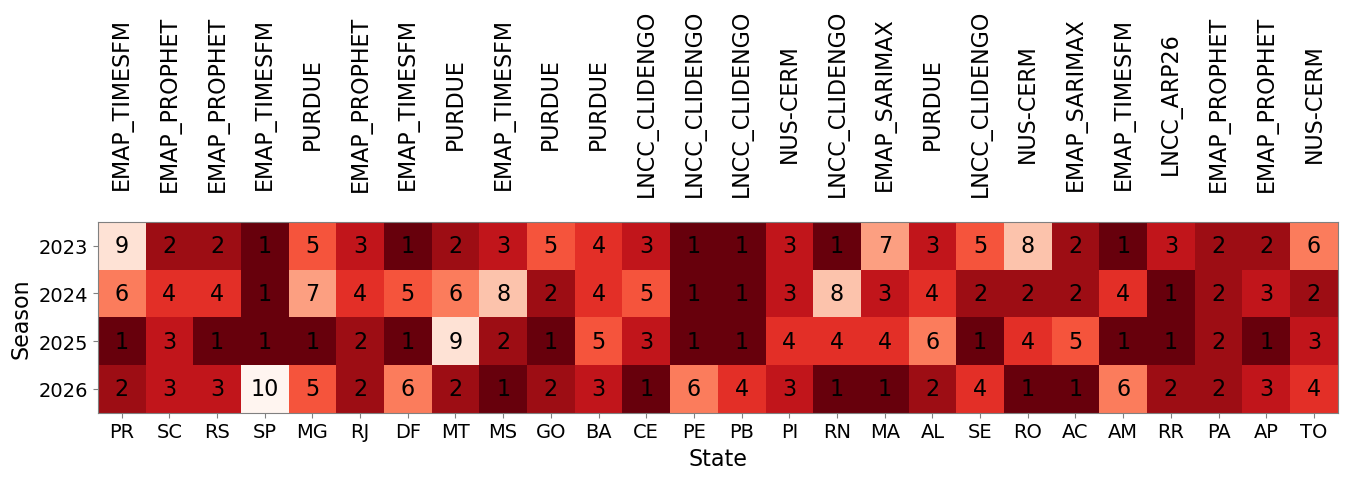

In [11]:
fig, ax = plt.subplots(figsize = (16, 3))

# Show as image
im = ax.imshow(df_pv.values, cmap="Reds_r")

# Add labels
ax.set_xticks(np.arange(df_pv.shape[1]))
ax.set_yticks(np.arange(df_pv.shape[0]))
ax.set_xticklabels(df_pv.columns)
ax.set_yticklabels(df_pv.index)

for i in range(df_pv.shape[0]):
    for j in range(df_pv.shape[1]):
        text = ax.text(j, i, int(df_pv.iloc[i, j]),
                       ha="center", va="center", color="black")

for j in range(df_pv.shape[1]):
    
    model = df_rank_by_model_st.loc[df_rank_by_model_st.state == df_pv.columns[j]].model.values[0]

    text = ax.text(j, -3, model,
                       ha="center", va="center", color="black", 
                       rotation=90)
        
ax.set_xlabel('State')
ax.set_ylabel('Season')

plt.savefig(f'figures/forecast_puzzle_{challenge}.png', dpi = 400, bbox_inches = 'tight')
plt.show()